# 🍷 Wine Quality Prediction - Progetto Capstone

## Contesto del Progetto

### Il Cliente: Cantina di Pregio Portoghese

La nostra cantina cliente, produttrice di **Vinho Verde** (vini verdi portoghesi), si trova di fronte a una sfida cruciale nel processo di produzione: **quale lotti di vino destinare all'affinamento in barrique** per ottenere vini di alta qualità destinati al mercato premium.

### La Richiesta dell'Enologo

L'enologo capo della cantina ci ha contattato con una richiesta specifica:

> *"Ogni anno produciamo centinaia di lotti di vino. Attualmente, la decisione su quali lotti far invecchiare nelle costose botti di rovere si basa principalmente sull'esperienza e sull'assaggio. Questo processo è:*
> - *Soggettivo e dipendente dalla disponibilità dell'enologo*
> - *Costoso in termini di tempo (richiede settimane per le valutazioni)*
> - *Rischioso: investiamo in barrique costose senza certezza del risultato finale*
>
> *Abbiamo bisogno di un sistema che, analizzando i parametri chimico-fisici del vino in fase iniziale, predica con affidabilità se un lotto merita l'investimento per l'affinamento premium."*

### Raccolta Dati

La cantina ha messo a disposizione il proprio **database storico** contenente:
- **Analisi chimico-fisiche** di oltre 6,000 campioni di vino
- **Valutazioni sensoriali** da parte di panel di esperti sommelier (score 0-10)
- Parametri misurati in laboratorio: acidità, pH, solfiti, alcol, residui zuccherini, ecc.

I dati provengono da:
1. **Laboratorio interno** della cantina (misure oggettive)
2. **Panel di degustazione certificato** (valutazione qualità)
3. **Archivio storico** delle decisioni di affinamento e risultati commerciali

### Dataset: UCI Wine Quality

Per questo progetto utilizziamo il dataset pubblico **UCI Wine Quality** (ID: 186), che rappresenta esattamente lo scenario descritto:
- **6,497 campioni** di vini Vinho Verde (rossi e bianchi)
- **11 variabili chimico-fisiche** misurate in laboratorio
- **Valutazione qualitativa** (0-10) da esperti enologi

### Obiettivo del Progetto

Sviluppare un **sistema di Machine Learning** che:
1. Predica la **probabilità che un vino sia di alta qualità** (score ≥ 7)
2. Supporta l'enologo nelle **decisioni di affinamento** 

### Deliverable

1. **Modello ML** addestrato e validato (pipeline scikit-learn)
2. **Webapp Streamlit** per l'utilizzo in cantina
3. **Sistema MLflow** per tracking e versionamento
4. **Explainability** (SHAP, Feature Importance) per trasparenza decisionale

---

## Esplorazione Dataset e Sviluppo Modello

In [1]:
from ucimlrepo import fetch_ucirepo 
import os
import mlflow

# Opt-in necessario nelle versioni recenti per usare il backend file legacy.
os.environ.setdefault("MLFLOW_ALLOW_FILE_STORE", "true")
mlflow.set_tracking_uri("file:mlruns")  


# fetch dataset 
wine_quality = fetch_ucirepo(id=186) 
  
# data (as pandas dataframes) 
X = wine_quality.data.features 
y = wine_quality.data.targets 
  
# metadata 
print(wine_quality.metadata) 
  
# variable information 
print(wine_quality.variables) 


c:\Users\a.ferri\OneDrive - UBroker SpA\Desktop\Ale\corso di formazione\CORSO_IA_DATA_ANALYSIS\ai_course_data_analysis\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'uci_id': 186, 'name': 'Wine Quality', 'repository_url': 'https://archive.ics.uci.edu/dataset/186/wine+quality', 'data_url': 'https://archive.ics.uci.edu/static/public/186/data.csv', 'abstract': 'Two datasets are included, related to red and white vinho verde wine samples, from the north of Portugal. The goal is to model wine quality based on physicochemical tests (see [Cortez et al., 2009], http://www3.dsi.uminho.pt/pcortez/wine/).', 'area': 'Business', 'tasks': ['Classification', 'Regression'], 'characteristics': ['Multivariate'], 'num_instances': 4898, 'num_features': 11, 'feature_types': ['Real'], 'demographics': [], 'target_col': ['quality'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2009, 'last_updated': 'Wed Nov 15 2023', 'dataset_doi': '10.24432/C56S3T', 'creators': ['Paulo Cortez', 'A. Cerdeira', 'F. Almeida', 'T. Matos', 'J. Reis'], 'intro_paper': {'ID': 252, 'type': 'NATIVE', 'title': 'Modeling wine preferences

In [2]:
# Binarizza la variabile y: 1 se quality >= 7, altrimenti 0
y_bin = (y['quality'] >= 7).astype(int)
# rename in high_quality
y_bin.rename('high_quality', inplace=True)
print(y_bin.value_counts())

high_quality
0    5220
1    1277
Name: count, dtype: int64


In [6]:
import pandas as pd

df_wine = pd.concat([X, y, y_bin.rename("high_quality")], axis=1)

display(df_wine.head())

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,high_quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0


In [7]:
df_wine

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,high_quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,5,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6492,6.2,0.21,0.29,1.6,0.039,24.0,92.0,0.99114,3.27,0.50,11.2,6,0
6493,6.6,0.32,0.36,8.0,0.047,57.0,168.0,0.99490,3.15,0.46,9.6,5,0
6494,6.5,0.24,0.19,1.2,0.041,30.0,111.0,0.99254,2.99,0.46,9.4,6,0
6495,5.5,0.29,0.30,1.1,0.022,20.0,110.0,0.98869,3.34,0.38,12.8,7,1


## Analisi descrittiva

Valutazione delle principali caratteristiche del dataset preso in oggetto.

,count,mean,std,min,25%,50%,75%,max,missing,missing_pct
fixed_acidity,6497.0,7.215307,1.296434,3.80000,6.40000,7.00000,7.70000,15.90000,0,0.0
volatile_acidity,6497.0,0.339666,0.164636,0.08000,0.23000,0.29000,0.40000,1.58000,0,0.0
citric_acid,6497.0,0.318633,0.145318,0.00000,0.25000,0.31000,0.39000,1.66000,0,0.0
residual_sugar,6497.0,5.443235,4.757804,0.60000,1.80000,3.00000,8.10000,65.80000,0,0.0
chlorides,6497.0,0.056034,0.035034,0.00900,0.03800,0.04700,0.06500,0.61100,0,0.0
free_sulfur_dioxide,6497.0,30.525319,17.749400,1.00000,17.00000,29.00000,41.00000,289.00000,0,0.0
total_sulfur_dioxide,6497.0,115.744574,56.521855,6.00000,77.00000,118.00000,156.00000,440.00000,0,0.0
density,6497.0,0.994697,0.002999,0.98711,0.99234,0.99489,0.99699,1.03898,0,0.0
pH,6497.0,3.218501,0.160787,2.72000,3.11000,3.21000,3.32000,4.01000,0,0.0
sulphates,6497.0,0.531268,0.148806,0.22000,0.43000,0.51000,0.60000,2.00000,0,0.0


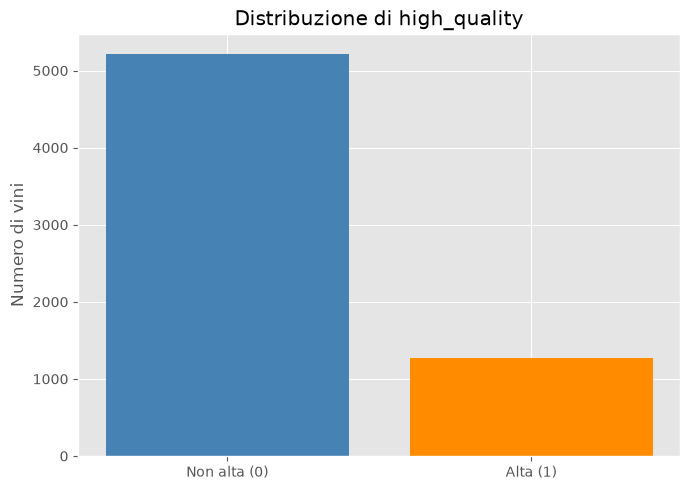

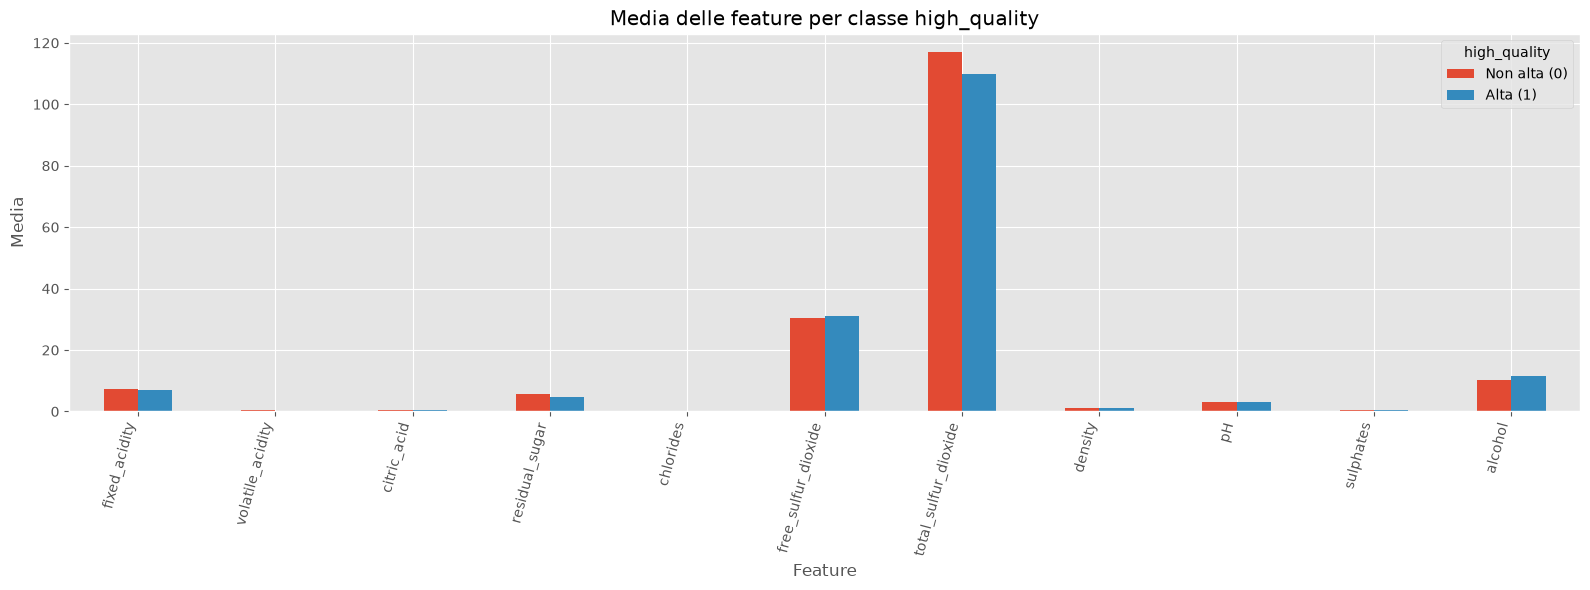

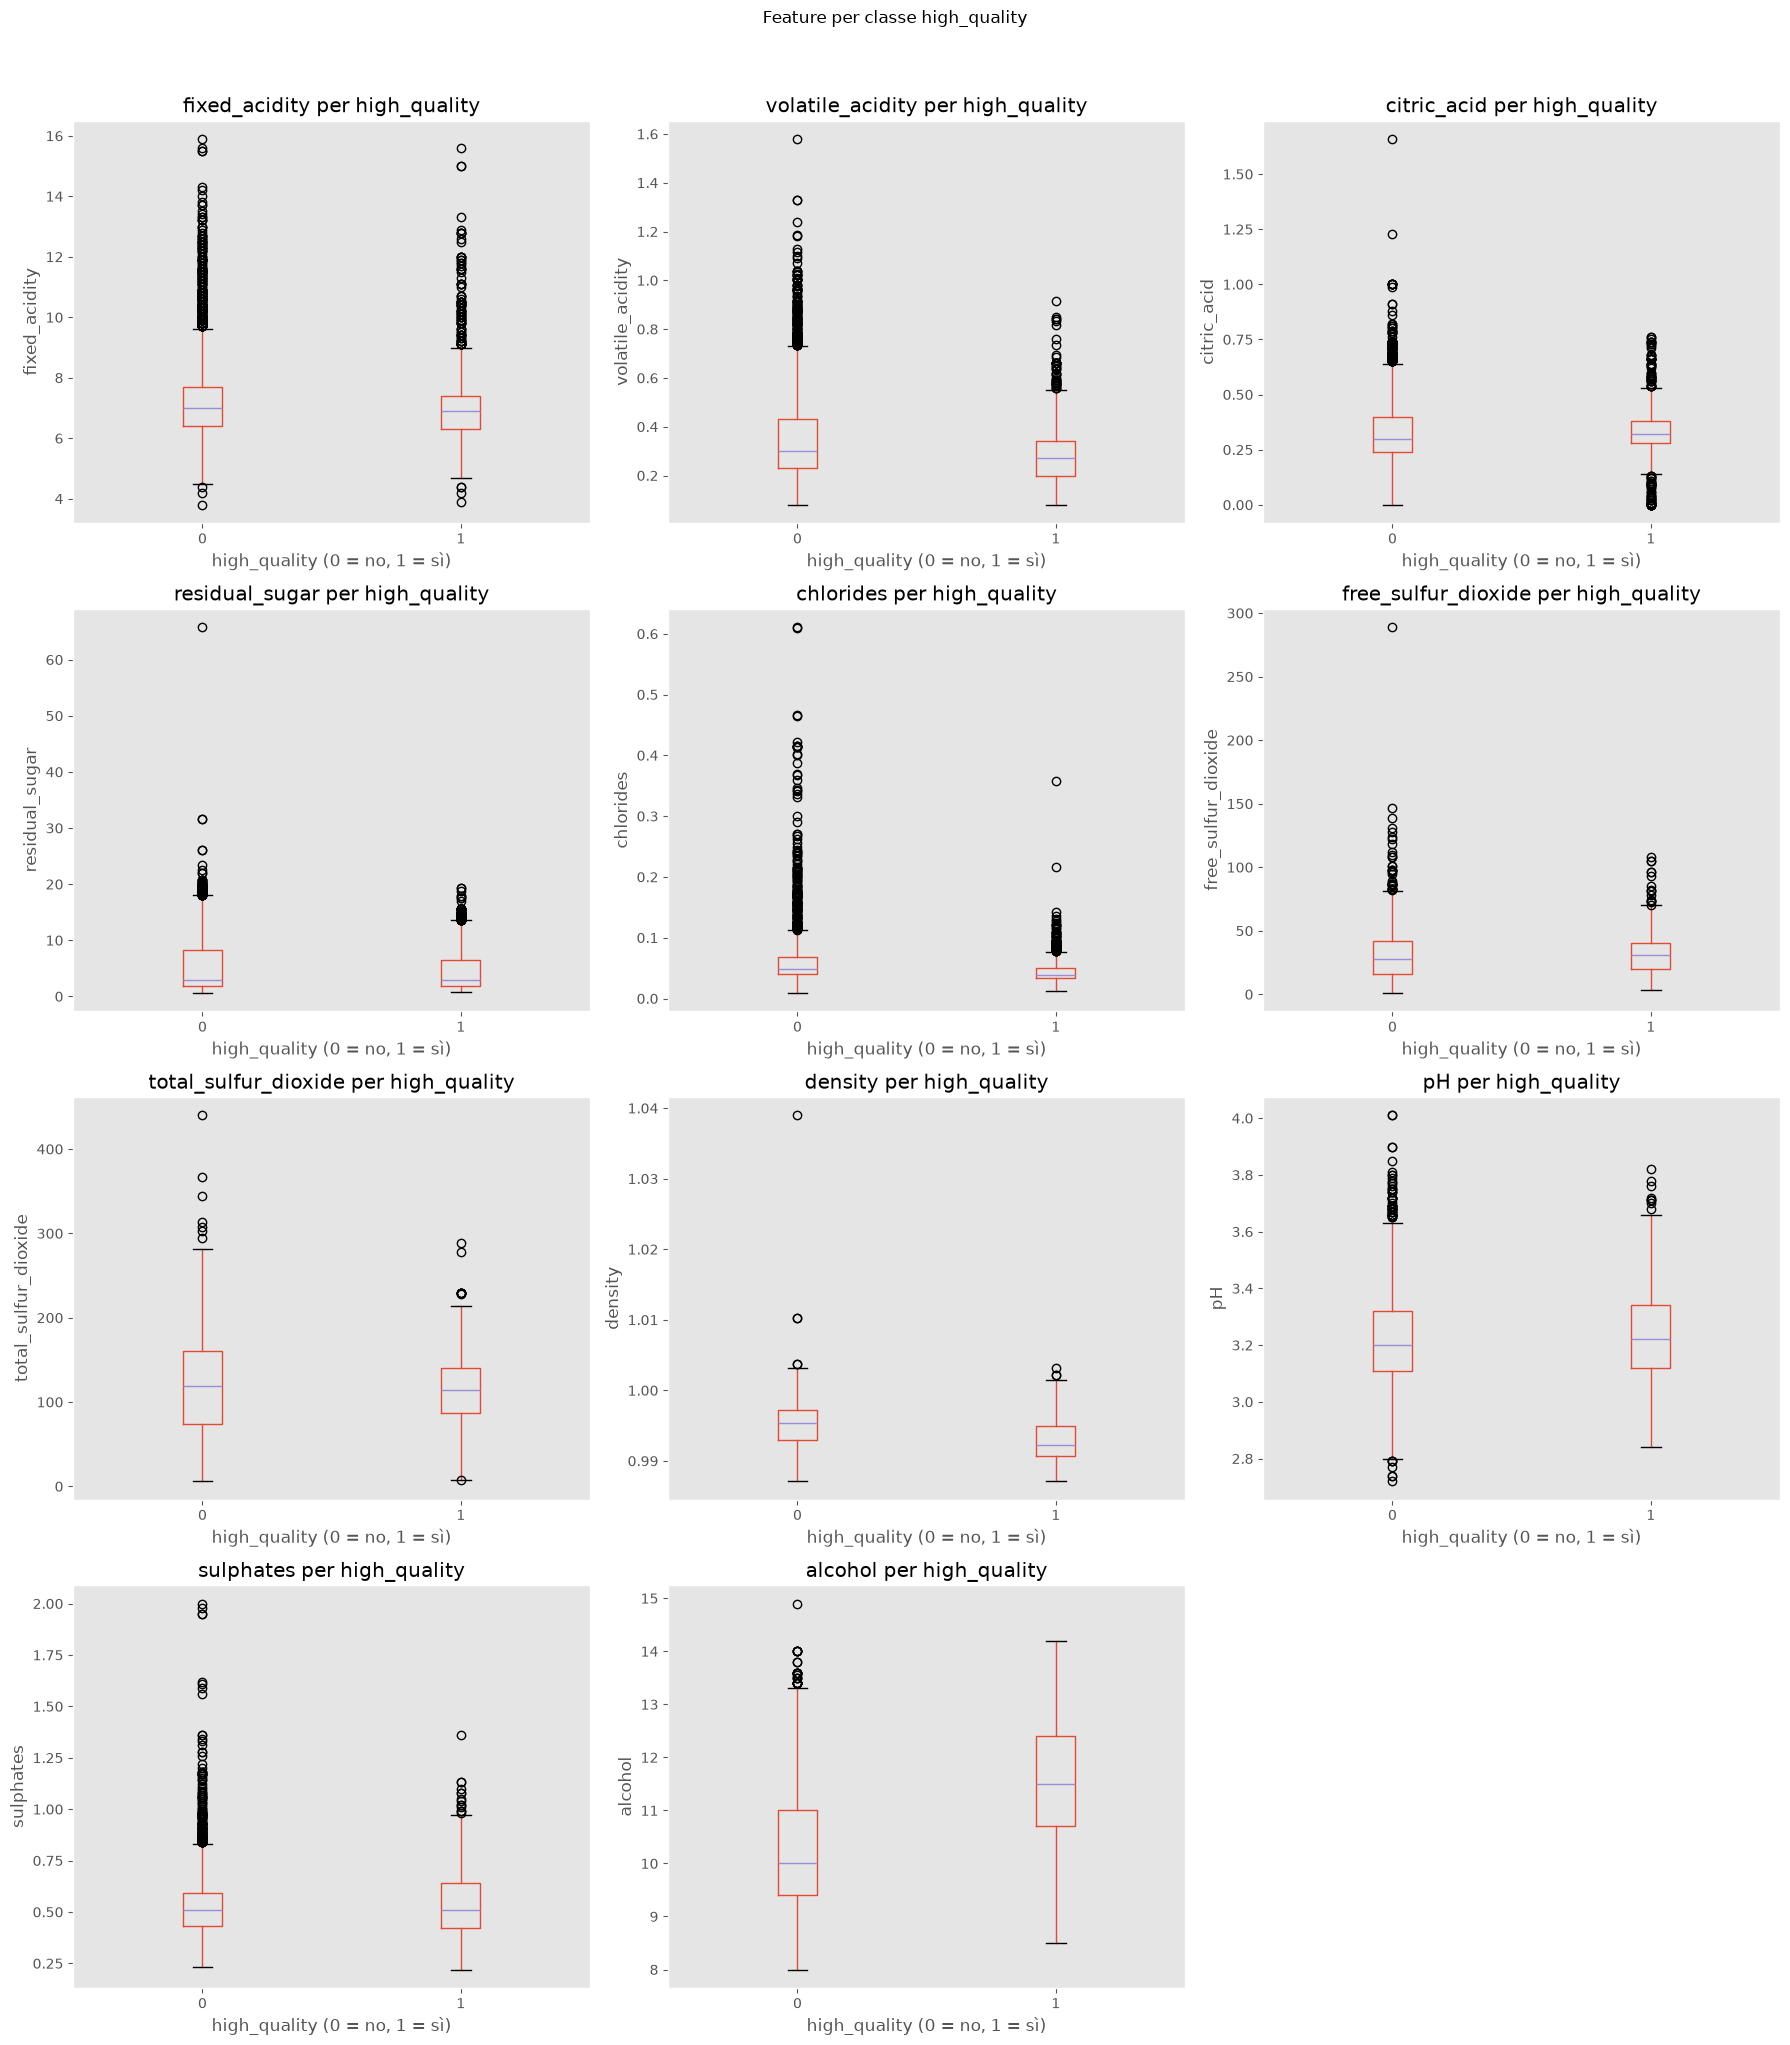

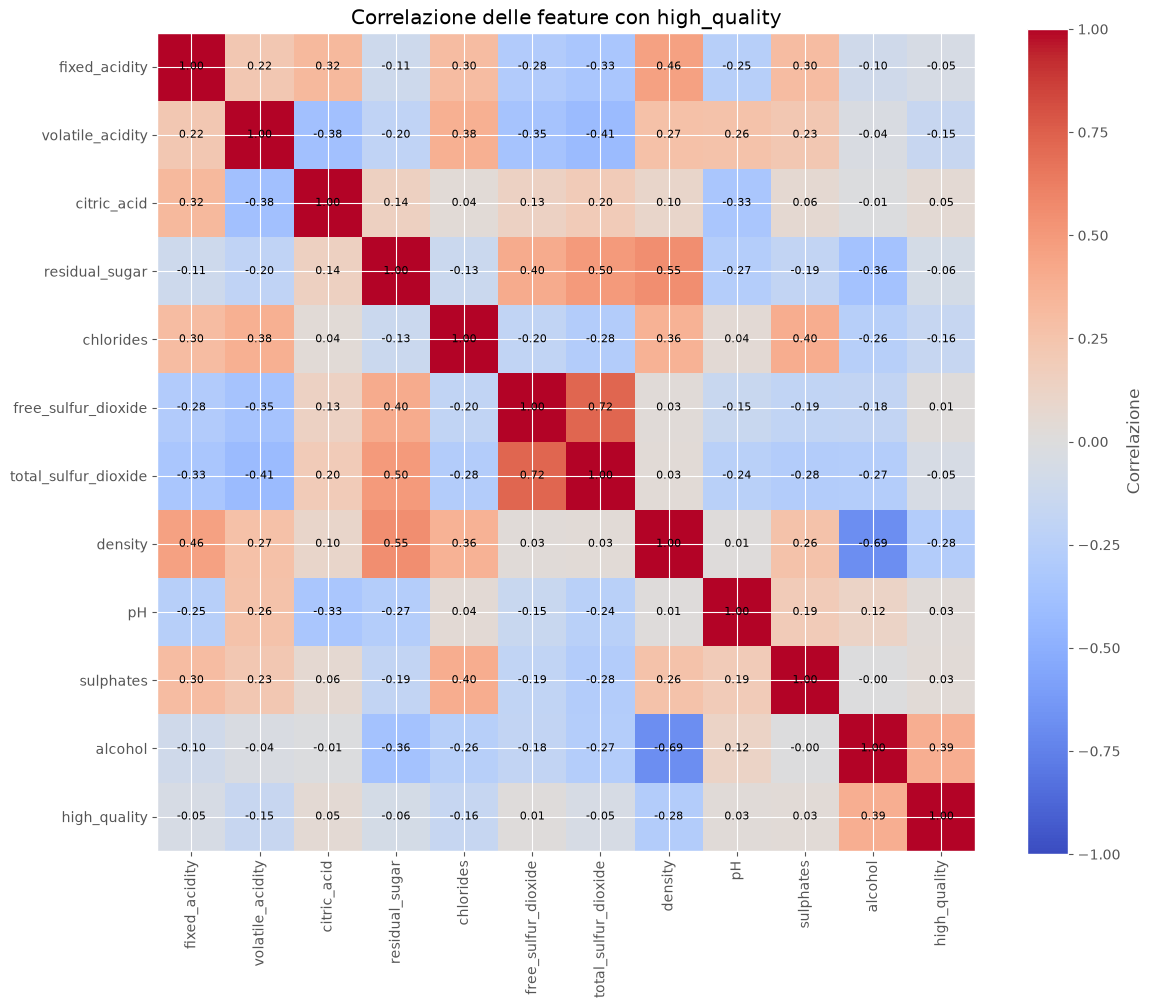

Dimensioni X: (6497, 11)
Valori di y: [np.int64(0), np.int64(1)]
Colonna quality presente in X: False


In [10]:
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Escludi quality dalle feature per evitare data leakage:
# high_quality deriva proprio da quality.
df_model = df_wine.drop(columns=["quality"], errors="ignore").copy()

# Target binario e feature per il modello
y = df_model["high_quality"].astype(int)
X = df_model.drop(columns=["high_quality"])

# Feature numeriche da analizzare
num_cols = X.select_dtypes(include="number").columns.tolist()

# 1) Statistiche descrittive e valori mancanti
df_analysis = pd.concat([X, y.rename("high_quality")], axis=1)

desc = df_analysis.describe(include="all").T
desc["missing"] = df_analysis.isna().sum()
desc["missing_pct"] = (desc["missing"] / len(df_analysis) * 100).round(2)
display(desc)

# 2) Distribuzione del target high_quality
class_counts = y.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(7, 5))
ax.bar(
    ["Non alta (0)", "Alta (1)"],
    [class_counts.get(0, 0), class_counts.get(1, 0)],
    color=["steelblue", "darkorange"]
)
ax.set_title("Distribuzione di high_quality")
ax.set_ylabel("Numero di vini")
plt.tight_layout()
plt.show()

# 3) Media delle feature per classe del target
class_means = df_analysis.groupby("high_quality")[num_cols].mean().T
class_means.plot(kind="bar", figsize=(16, 6))
plt.title("Media delle feature per classe high_quality")
plt.xlabel("Feature")
plt.ylabel("Media")
plt.legend(["Non alta (0)", "Alta (1)"], title="high_quality")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()

# 4) Boxplot delle feature rispetto a high_quality
cols = 3
rows = int(np.ceil(len(num_cols) / cols))
fig, axes = plt.subplots(rows, cols, figsize=(18, 5 * rows))
axes = np.array(axes).reshape(-1)

for i, feature in enumerate(num_cols):
    df_analysis.boxplot(
        column=feature,
        by="high_quality",
        ax=axes[i],
        grid=False
    )
    axes[i].set_title(f"{feature} per high_quality")
    axes[i].set_xlabel("high_quality (0 = no, 1 = sì)")
    axes[i].set_ylabel(feature)

for ax in axes[len(num_cols):]:
    ax.axis("off")

fig.suptitle("Feature per classe high_quality", y=1.02)
plt.tight_layout()
plt.show()

# 5) Correlazione delle feature con il target binario
corr_data = pd.concat([X[num_cols], y.rename("high_quality")], axis=1)
corr = corr_data.corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(12, 10))
image = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)

ax.set_xticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticks(range(len(corr.index)))
ax.set_yticklabels(corr.index)
ax.set_title("Correlazione delle feature con high_quality")

for row in range(len(corr.index)):
    for col in range(len(corr.columns)):
        ax.text(
            col,
            row,
            f"{corr.iloc[row, col]:.2f}",
            ha="center",
            va="center",
            fontsize=8
        )

fig.colorbar(image, ax=ax, label="Correlazione")
plt.tight_layout()
plt.show()

# Verifica: quality non deve essere presente tra le feature
print("Dimensioni X:", X.shape)
print("Valori di y:", sorted(y.unique()))
print("Colonna quality presente in X:", "quality" in X.columns)

---

## 📋 Guida al Progetto

### Requisiti Minimi 

Per completare il progetto, è **necessario** eseguire i seguenti passi:

1. ✅ **Allenare un modello di Machine Learning**
   - Utilizzare i dati del wine quality dataset
   - Creare una pipeline scikit-learn completa (preprocessing + model)
   - Valutare le performance del modello

2. ✅ **Loggare il modello su MLflow**
   - Configurare MLflow tracking
   - Loggare parametri, metriche e artefatti del modello
   - Salvare la pipeline completa con `mlflow.sklearn.log_model(..., serialization_format="cloudpickle")` (come in T4)

   💡 La sidebar della webapp mostra le metriche **solo** se sono loggate con questi nomi esatti: `accuracy`, `precision`, `recall`, `f1_score`, `roc_auc`

3. ✅ **Registrare il modello nel Model Registry**
   - Registrare il modello con nome `wine_clf`
   - Assegnare l'alias `@production` alla versione migliore
   - Verificare che il modello sia accessibile via registry

4. ✅ **Testare la Webapp**
   - Eseguire `uv run streamlit run app.py` dalla cartella `capstone_project`
   - Verificare che carichi correttamente il modello
   - Testare le predizioni con diversi parametri

---

### Passi Avanzati (Opzionali ma Consigliati)

Una volta completati i requisiti minimi, potete approfondire con:

#### **1. Valutazione Avanzata delle Performance**

**Metriche sul Test Set:**
- Calcolare **ROC-AUC** per valutare la capacità discriminativa
- Analizzare **Precision-Recall Curve** per trovare il trade-off ottimale
- Confrontare diverse soglie di classificazione

**Domanda Critica da Rispondere:**
> Nel contesto della cantina, **quale errore è più costoso?**
> - **Falso Positivo**: Affinare in barrique un vino che poi risulta mediocre → spreco investimento
> - **Falso Negativo**: Non affinare un vino eccellente → perdita opportunità di vendita premium
> 
> In base alla risposta, ottimizzare per **Precision** (minimizzare FP) o **Recall** (minimizzare FN)

#### **2. Model Comparison e Selection**

- **Testare diversi algoritmi**:
  - Random Forest (baseline)
  - Logistic Regression (interpretabilità)
  - SVM con kernel RBF
  
- **Loggare tutti i modelli su MLflow** per confronto sistematico
- **Selezionare il migliore** in base a metrica rilevante + interpretabilità

#### **3. Explainability e Feature Importance**

**Permutation Feature Importance (PFI):**
- Identificare quali feature contribuiscono maggiormente alle predizioni
- Loggare plot PFI come artefatto MLflow

**SHAP Values:**
- Calcolare SHAP values per interpretabilità locale
- Generare summary plot e dependence plot
- Loggare visualizzazioni su MLflow

**Domande da Esplorare:**
- Quali parametri chimico-fisici sono più importanti per la qualità?
- Ci sono interazioni tra feature? (es. alcol + acidità)
- Il modello è allineato con la conoscenza enologica?

#### **4. Iterazione e Miglioramento**

1. **Esplorare le diverse run MLflow**:
   - Usare MLflow UI: `MLFLOW_ALLOW_FILE_STORE=true uv run mlflow ui --backend-store-uri file:mlruns --port 5000` (dalla cartella `capstone_project`)
   - Confrontare run parallele
   - Identificare pattern nei parametri vincenti

2. **Aggiornare la webapp**:
   - Registrare il modello migliorato con alias `@production`
   - Riavviare la webapp
   - Verificare che le predizioni siano migliorate

3. **Documentare il processo**:
   - Motivare la scelta del modello finale
   - Spiegare il trade-off precision/recall scelto
   - Documentare le feature più importanti

---

**Iniziate con i requisiti minimi, poi espandete progressivamente con i passi avanzati!**

## 1. ✅ **Allenare un modello di Machine Learning**
   - Utilizzare i dati del wine quality dataset
   - Creare una pipeline scikit-learn completa (preprocessing + model)
   - Valutare le performance del modello

In [11]:
import numpy as np
from scipy.stats import norm
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

import statsmodels.api as sm



class ProbitClassifier(ClassifierMixin, BaseEstimator):
    """Classificatore Probit compatibile con le API scikit-learn."""

    def __init__(self, max_iter=200):
        self.max_iter = max_iter

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=int)
        self.classes_ = np.unique(y)

        if len(self.classes_) != 2 or not np.array_equal(self.classes_, [0, 1]):
            raise ValueError("ProbitClassifier richiede un target binario codificato 0/1.")

        X_const = sm.add_constant(X, has_constant="add")
        self.result_ = sm.Probit(y, X_const).fit(
            maxiter=self.max_iter,
            disp=False
        )
        return self

    def predict_proba(self, X):
        X = np.asarray(X, dtype=float)
        X_const = sm.add_constant(X, has_constant="add")
        probability_1 = norm.cdf(X_const @ self.result_.params)
        probability_1 = np.clip(probability_1, 0, 1)
        return np.column_stack((1 - probability_1, probability_1))

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)


# X e y sono già definiti nelle celle precedenti.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

positive_weight = (y_train == 0).sum() / (y_train == 1).sum()

# pipelines di tutti i modelli in unico passaggio

pipelines = {
    "logistic": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=42
        ))
    ]),
    "probit": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", ProbitClassifier(max_iter=200))
    ]),
    "random_forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]),
    "xgboost": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", XGBClassifier(
            n_estimators=300,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.9,
            colsample_bytree=0.9,
            scale_pos_weight=positive_weight,
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        ))
    ])
}

# Addestramento e valutazione sul test set
results = []

for name, pipeline in pipelines.items():
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)
    probabilities = pipeline.predict_proba(X_test)[:, 1]

    results.append({
        "modello": name,
        "accuracy": accuracy_score(y_test, predictions),
        "precision": precision_score(y_test, predictions, zero_division=0),
        "recall": recall_score(y_test, predictions, zero_division=0),
        "f1_score": f1_score(y_test, predictions, zero_division=0),
        "roc_auc": roc_auc_score(y_test, probabilities)
    })

results_df = pd.DataFrame(results).set_index("modello").sort_values(
    "roc_auc", ascending=False
)
display(results_df)

,accuracy,precision,recall,f1_score,roc_auc
modello,,,,,
random_forest,0.886154,0.723140,0.683594,0.702811,0.912005
xgboost,0.810000,0.511392,0.789062,0.620584,0.884223
probit,0.823077,0.627451,0.250000,0.357542,0.802371
logistic,0.716923,0.387550,0.753906,0.511936,0.800310


PermutationExplainer explainer: 101it [00:13,  7.40it/s]                         


SHAP — logistic


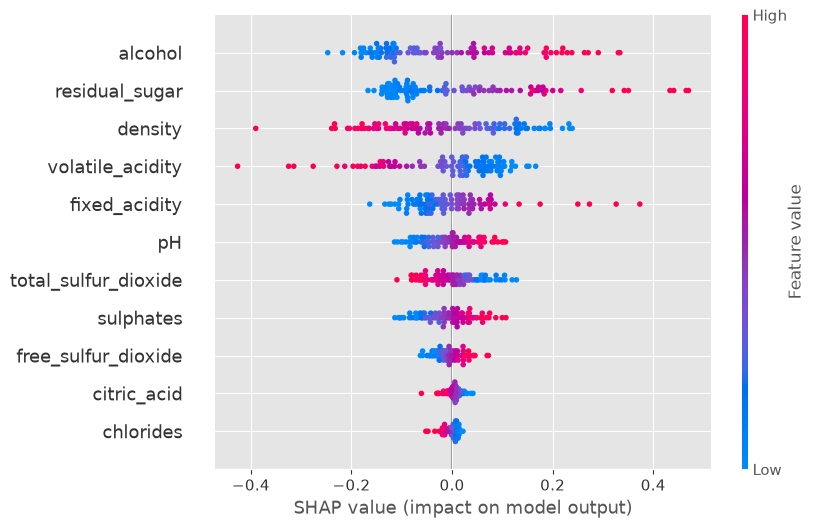

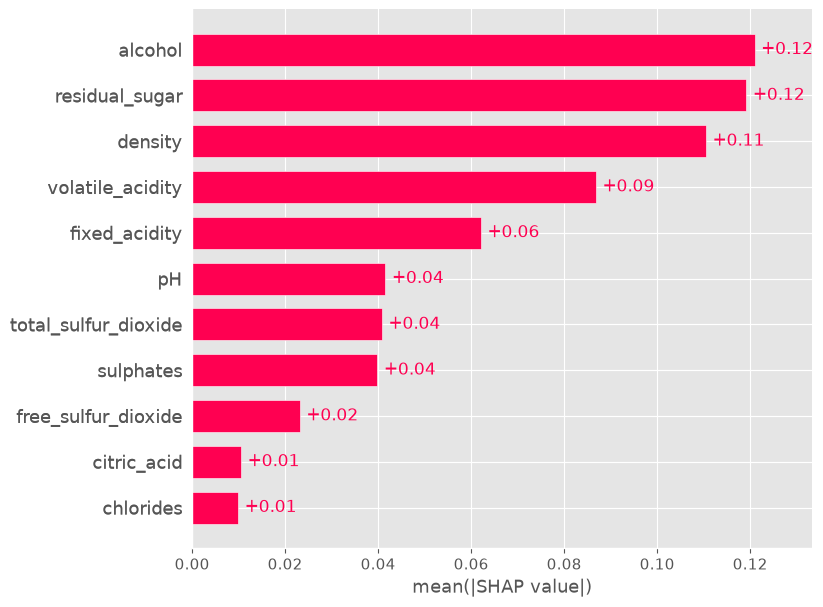

SHAP — probit


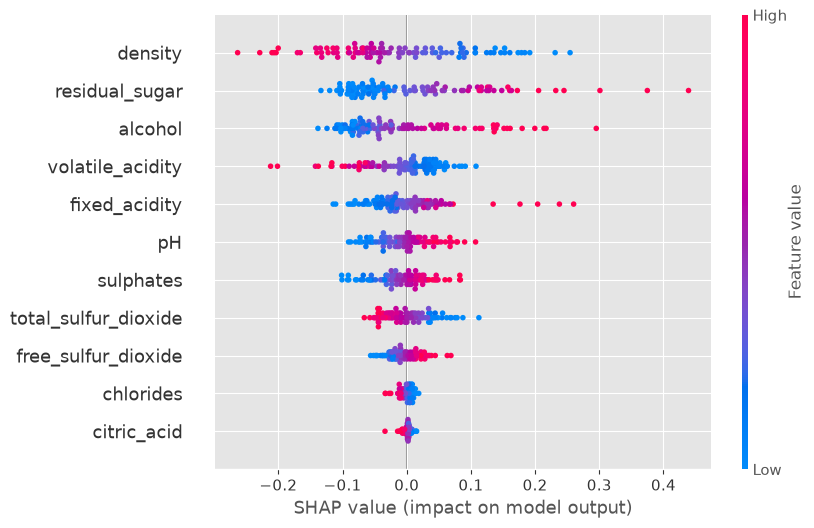

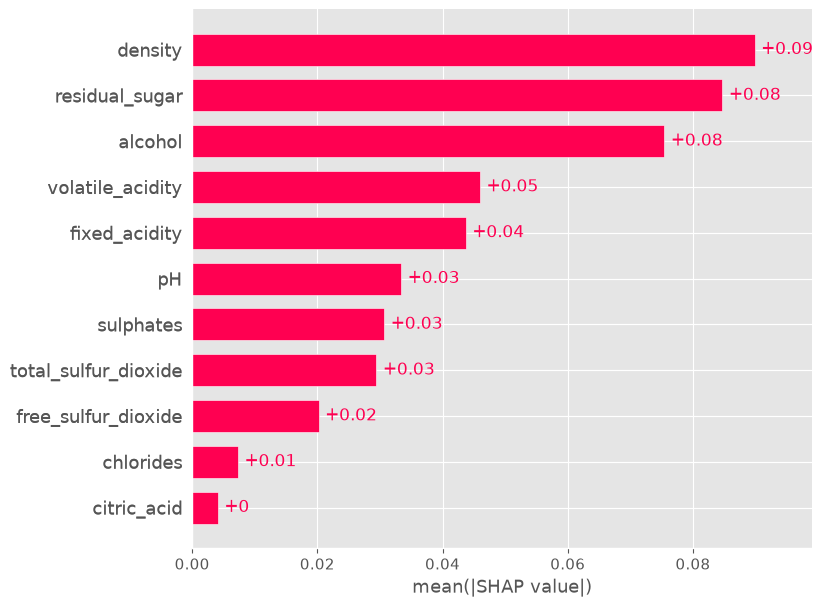

PermutationExplainer explainer: 101it [00:19,  2.45it/s]                         


SHAP — random_forest


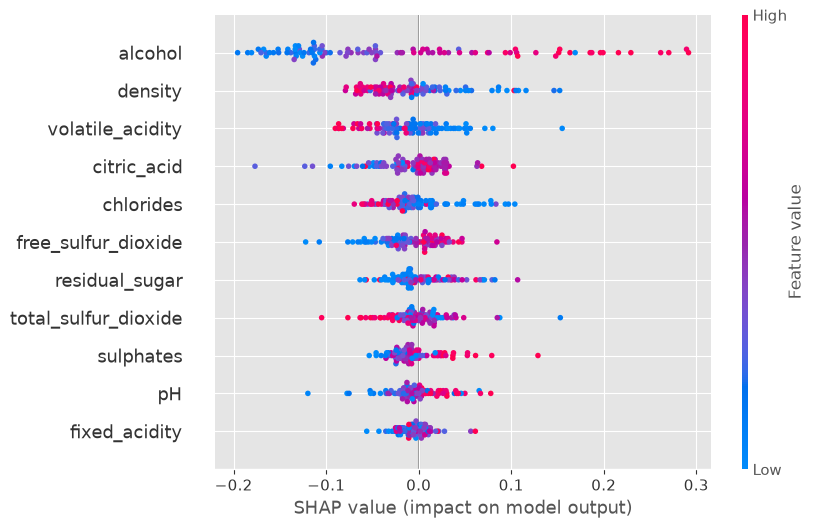

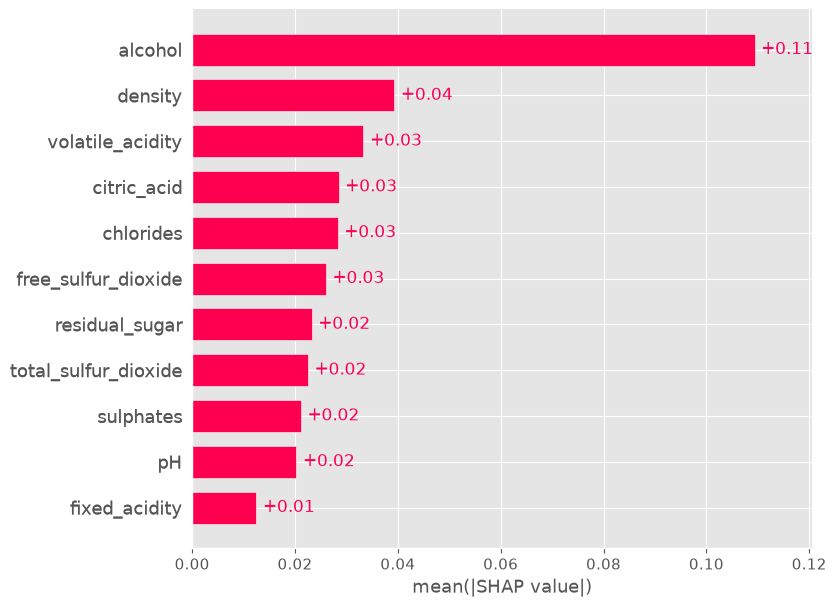

SHAP — xgboost


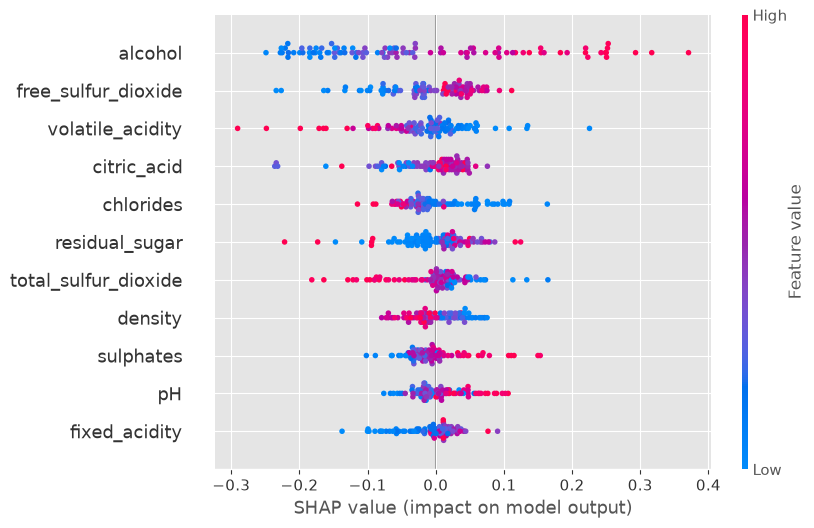

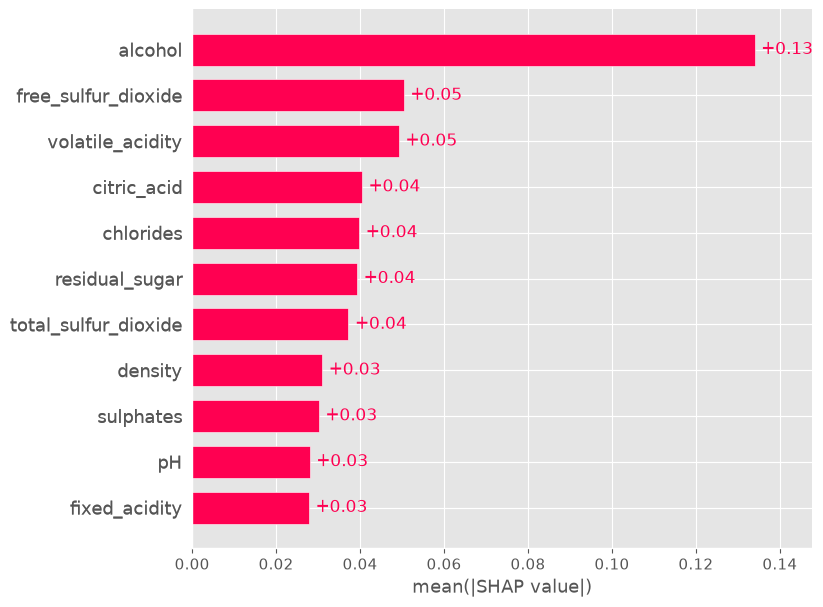

,logistic,probit,random_forest,xgboost
alcohol,0.1209,0.0754,0.1094,0.1339
density,0.1105,0.0898,0.0393,0.0310
residual_sugar,0.1191,0.0847,0.0232,0.0393
volatile_acidity,0.0868,0.0460,0.0333,0.0492
fixed_acidity,0.0621,0.0437,0.0125,0.0278
total_sulfur_dioxide,0.0408,0.0294,0.0225,0.0372
pH,0.0415,0.0334,0.0203,0.0280
sulphates,0.0398,0.0307,0.0211,0.0302
free_sulfur_dioxide,0.0231,0.0202,0.0260,0.0504
chlorides,0.0099,0.0073,0.0283,0.0398


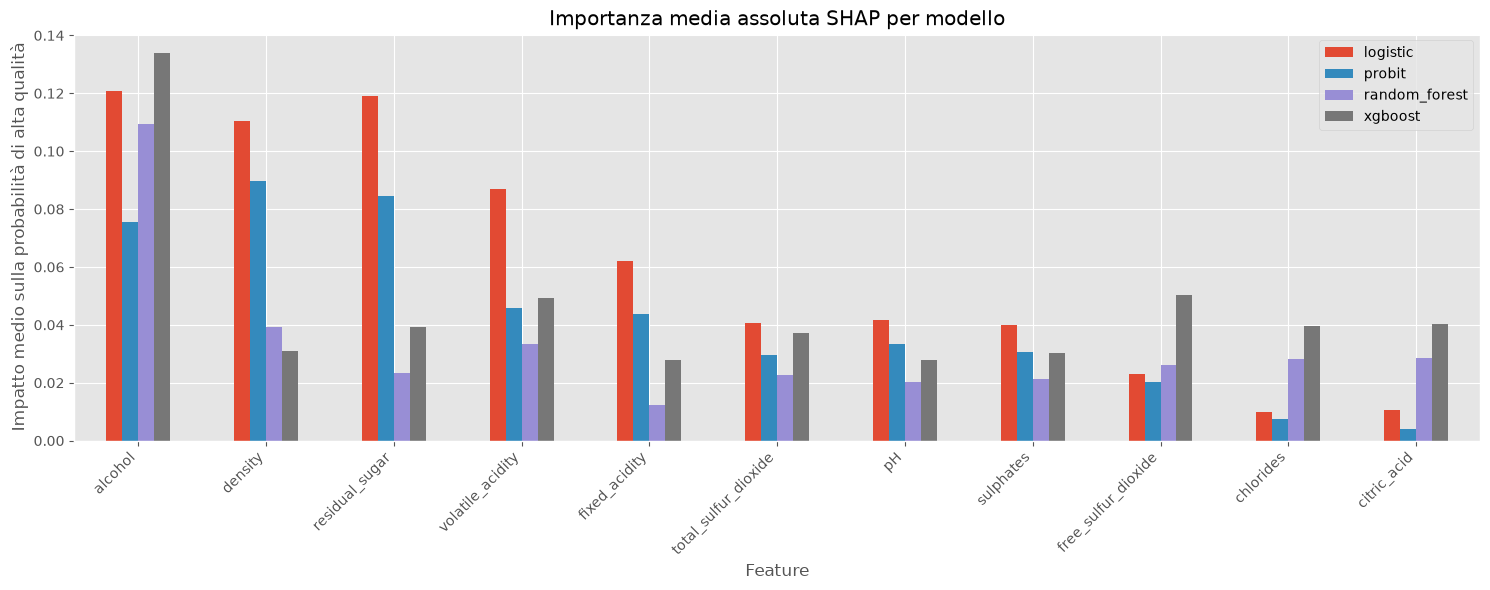

In [12]:
import shap

# Campioni usati per la spiegazione
background = shap.sample(X_train, min(50, len(X_train)), random_state=42)
X_explain = X_test.sample(min(100, len(X_test)), random_state=42)
max_evals = 2 * X.shape[1] + 1

shap_values_by_model = {}
importance_by_model = {}

for model_name, fitted_pipeline in pipelines.items():
    def predict_positive(data, model=fitted_pipeline):
        # SHAP può passare un array NumPy: ripristina i nomi e l'ordine delle feature.
        if isinstance(data, pd.DataFrame):
            data_frame = data
        else:
            data_frame = pd.DataFrame(data, columns=X.columns)
        return model.predict_proba(data_frame)[:, 1]

    explainer = shap.Explainer(
        predict_positive,
        masker=background,
        algorithm="permutation",
        feature_names=X.columns.tolist()
    )

    shap_values = explainer(X_explain, max_evals=max_evals)
    shap_values_by_model[model_name] = shap_values

    importance_by_model[model_name] = (
        np.abs(shap_values.values).mean(axis=0)
    )

    print(f"SHAP — {model_name}")
    shap.plots.beeswarm(shap_values, max_display=X.shape[1])
    shap.plots.bar(shap_values, max_display=X.shape[1])

# Confronto dell'importanza media delle feature tra i quattro modelli
importance_df = pd.DataFrame(importance_by_model, index=X.columns)
importance_df = importance_df.loc[
    importance_df.mean(axis=1).sort_values(ascending=False).index
]

display(importance_df.round(4))

ax = importance_df.plot(kind="bar", figsize=(15, 6))
ax.set_title("Importanza media assoluta SHAP per modello")
ax.set_xlabel("Feature")
ax.set_ylabel("Impatto medio sulla probabilità di alta qualità")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 2. ✅ **Loggare il modello su MLflow**
   - Configurare MLflow tracking
   - Loggare parametri, metriche e artefatti del modello
   - Salvare la pipeline completa con `mlflow.sklearn.log_model(..., serialization_format="cloudpickle")` (come in T4)

In [20]:
import os
import tempfile
from pathlib import Path

# Necessario con alcune versioni di MLflow che usano il backend file.
os.environ.setdefault("MLFLOW_ALLOW_FILE_STORE", "true")

import mlflow
import mlflow.sklearn
import pandas as pd

# Store MLflow: cartella mlruns annidata in capstone_project
mlruns_path = Path(
    r"C:\Users\a.ferri\OneDrive - UBroker SpA\Desktop\Ale\corso di formazione\CORSO_IA_DATA_ANALYSIS\ai_course_data_analysis\mlruns"
)

if not mlruns_path.is_dir():
    raise FileNotFoundError(f"Cartella MLflow non trovata: {mlruns_path}")

tracking_uri = mlruns_path.as_uri()
mlflow.set_tracking_uri(tracking_uri)
mlflow.set_experiment("wine-quality")

print("Tracking URI:", mlflow.get_tracking_uri())

metriche_da_loggare = [
    "accuracy",
    "precision",
    "recall",
    "f1_score",
    "roc_auc",
]

for model_name, pipeline in pipelines.items():
    if model_name not in results_df.index:
        raise ValueError(
            f"Il modello {model_name!r} non è presente nell'indice di results_df."
        )

    metriche_mancanti = [
        metric
        for metric in metriche_da_loggare
        if metric not in results_df.columns
    ]
    if metriche_mancanti:
        raise ValueError(
            f"In results_df mancano queste metriche: {metriche_mancanti}"
        )

    model_metrics = results_df.loc[model_name]

    with mlflow.start_run(run_name=f"wine_quality_{model_name}") as run:
        mlflow.log_params({
            "model_name": model_name,
            "selection_metric": "roc_auc",
            "random_state": 42,
            "test_size": 0.20,
        })

        # I nomi delle metriche corrispondono a quelli richiesti dalla webapp.
        mlflow.log_metrics({
            metric: float(model_metrics[metric])
            for metric in metriche_da_loggare
        })

        # Registra la pipeline completa nella run.
        mlflow.sklearn.log_model(
            sk_model=pipeline,
            name="model",
            input_example=X_train.head(3),
            serialization_format="cloudpickle",
        )

        # Registra le importanze SHAP, se già calcolate per questo modello.
        if (
            "importance_by_model" in globals()
            and model_name in importance_by_model
        ):
            shap_importance = pd.DataFrame({
                "feature": X.columns,
                "mean_abs_shap": importance_by_model[model_name],
            }).sort_values("mean_abs_shap", ascending=False)

            with tempfile.TemporaryDirectory() as temp_dir:
                importance_path = os.path.join(
                    temp_dir,
                    "shap_importance.csv",
                )
                shap_importance.to_csv(importance_path, index=False)
                mlflow.log_artifact(
                    importance_path,
                    artifact_path="explainability",
                )

        print(f"Modello loggato: {model_name}")
        print(f"Run ID: {run.info.run_id}")

2026/10/08 15:25:41 INFO mlflow.tracking.fluent: Experiment with name 'wine-quality' does not exist. Creating a new experiment.


Tracking URI: file:///C:/Users/a.ferri/OneDrive%20-%20UBroker%20SpA/Desktop/Ale/corso%20di%20formazione/CORSO_IA_DATA_ANALYSIS/ai_course_data_analysis/mlruns


2026/10/08 15:25:41 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
c:\Users\a.ferri\OneDrive - UBroker SpA\Desktop\Ale\corso di formazione\CORSO_IA_DATA_ANALYSIS\ai_course_data_analysis\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can decl

Modello loggato: logistic
Run ID: 5beb08fc81344b4d82bf98df97a42e25


2026/10/08 15:25:51 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
c:\Users\a.ferri\OneDrive - UBroker SpA\Desktop\Ale\corso di formazione\CORSO_IA_DATA_ANALYSIS\ai_course_data_analysis\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can decl

Modello loggato: probit
Run ID: 312ecb6d2b834f7daa1b2d924a3a694a


2026/10/08 15:26:03 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
c:\Users\a.ferri\OneDrive - UBroker SpA\Desktop\Ale\corso di formazione\CORSO_IA_DATA_ANALYSIS\ai_course_data_analysis\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can decl

Modello loggato: random_forest
Run ID: 9e499ab5288a405bb1e5b972bd93ca79


2026/10/08 15:26:17 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
c:\Users\a.ferri\OneDrive - UBroker SpA\Desktop\Ale\corso di formazione\CORSO_IA_DATA_ANALYSIS\ai_course_data_analysis\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can decl

Modello loggato: xgboost
Run ID: f8736092243948e298f3df2ea4d32272


## 3. ✅ **Registrare il modello nel Model Registry**
   - Registrare il modello con nome `wine_clf`
   - Assegnare l'alias `@production` alla versione migliore
   - Verificare che il modello sia accessibile via registry

## 4. ✅ **Testare la Webapp**
   - Eseguire `uv run streamlit run app.py` dalla cartella `capstone_project`
   - Verificare che carichi correttamente il modello
   - Testare le predizioni con diversi parametri

### Nota Importante

Il codice riportato sotto deve essere eseguito **alla fine** del workflow. Questo passaggio è necessario per salvare il modello migliore in una cartella locale, che potrà essere utilizzata per il **deploy** su **Streamlit Cloud**. 

Assicurati che il modello sia stato registrato e che la versione in produzione sia stata correttamente selezionata prima di eseguire il codice.

In [ ]:
import shutil
import mlflow
import mlflow.sklearn
from mlflow.tracking import MlflowClient

# Inizializza client MLflow
client = MlflowClient()
# Nome del modello registrato
model_name = "wine_clf"

model_uri = f"models:/{model_name}@production"

# Carica il modello
model = mlflow.sklearn.load_model(model_uri)

# Salva il modello in una cartella locale (model/model.pkl, letto dalla webapp come fallback)
shutil.rmtree("model", ignore_errors=True)  # sovrascrive un eventuale export precedente
mlflow.sklearn.save_model(model, "model", serialization_format="cloudpickle")
